# 14 · Explainable AI

## Purpose

Measure global permutation importance on a validation partition and attempt SHAP global and local plots when the installed model and dependency support them.

## Method

Fit the selected CV model on a training subset and evaluate permutation importance on a held-out part of the training split. SHAP uses a small sample; any failure falls back to permutation importance.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

Importance describes model reliance under this data distribution, not a causal effect. Correlated features can divide or mask importance.

## References

Lundberg & Lee (2017): https://proceedings.neurips.cc/paper_files/paper/2017/hash/8a20a8621978632d76c43dfd28b67767-Abstract.html


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '14 · Explainable AI')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 14 · Explainable AI


,feature,importance_mean_roc_auc_decrease,importance_std
0,product_category,0.024152,0.001088
1,shipping_method,0.021701,0.001481
2,used_coupon,0.016331,0.001495
3,payment_method,0.011929,0.000676
4,device_type,0.011128,0.000750
5,product_price,0.003178,0.000694
6,session_length_minutes,0.001784,0.000105
7,num_product_views,0.001249,0.000364
8,discount_percent,0.001098,0.000156
9,customer_age,0.000133,0.000107


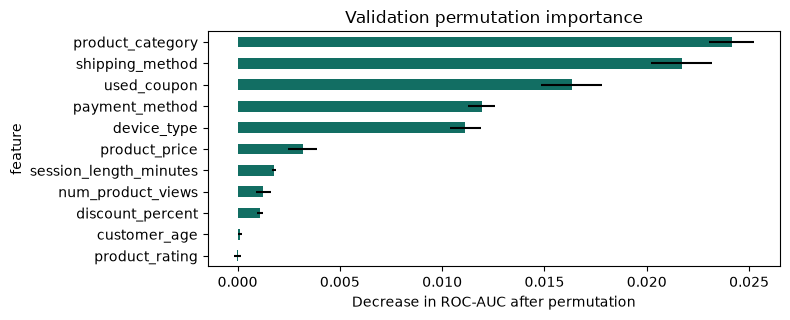

SHAP unavailable for this model or environment: SHAP is not installed; use permutation importance for a valid model-agnostic explanation.
Permutation importance remains the model-agnostic fallback.


In [2]:
from returnwise.explain import permutation_importance_table, shap_explanation
from returnwise.models import fit_best_model
from returnwise.research_state import load_state, save_state
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import pandas as pd

state = load_state()
X_train, y_train = state['X_train'], state['y_train']
x_fit, x_valid, y_fit, y_valid = train_test_split(X_train, y_train, test_size=0.20, random_state=42, stratify=y_train)
params = (state.get('tuning_result') or {}).get('pipeline_parameters') if (state.get('tuning_result') or {}).get('model') == state['selected_model'] else None
explain_model = fit_best_model(x_fit, y_fit, state['selected_model'], mode=state.get('experiment_mode', 'quick'), seed=42, parameters=params)
importance = permutation_importance_table(explain_model, x_valid, y_valid, repeats=5, seed=42)
display(importance)
ax = importance.head(20).sort_values('importance_mean_roc_auc_decrease').plot.barh(
    x='feature', y='importance_mean_roc_auc_decrease', xerr='importance_std',
    figsize=(8, max(3, min(20, len(importance)) * 0.3)), legend=False, color='#126E63',
    title='Validation permutation importance'
)
ax.set_xlabel('Decrease in ROC-AUC after permutation')
plt.tight_layout()
plt.show()
shap_status = 'not attempted'
try:
    explanation = shap_explanation(explain_model, x_valid, max_rows=200)
    import shap
    shap.plots.beeswarm(explanation, max_display=15, show=False)
    plt.tight_layout()
    plt.show()
    shap_status = 'summary plot completed'
    try:
        top_feature = importance.iloc[0]['feature']
        shap.plots.scatter(explanation[:, top_feature], color=explanation, show=False)
        plt.tight_layout()
        plt.show()
        shap_status += '; dependence scatter completed'
    except Exception as dependence_error:
        print('SHAP dependence plot unavailable:', dependence_error)
    try:
        shap.plots.waterfall(explanation[0], max_display=12, show=False)
        plt.tight_layout()
        plt.show()
        shap_status += '; one local waterfall completed'
    except Exception as local_error:
        print('Local SHAP waterfall unavailable:', local_error)
except Exception as error:
    print('SHAP unavailable for this model or environment:', error)
    print('Permutation importance remains the model-agnostic fallback.')
state.update({'permutation_importance': importance.to_dict(orient='records'), 'shap_status': shap_status})
from returnwise.experiments import log_experiment
log_experiment('Explainable AI feature importance', None,
               {'permutation_importance': importance.head(20).to_dict(orient='records')},
               {'model': state['selected_model'], 'shap_status': shap_status})
save_state(state)
